### Taxonomy Barplot


Import libraries and set working directory

In [11]:
import os
import pandas as pd
import qiime2 as q2
from qiime2 import Visualization
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
from biom import Table
import tempfile

%cd /home/jovyan/MicroOdyssey_clean

meta_dir= "data"
bracken_dir= "output/02_taxonomicclassification"
output_dir= "output/02_taxonomicclassification"

/home/jovyan/MicroOdyssey_clean


In [2]:
import os

print(os.getcwd())
print(os.path.abspath(meta_dir))
print(os.path.exists(f"{meta_dir}/metadata.tsv"))

/home/jovyan/MicroOdyssey_clean
/home/jovyan/MicroOdyssey_clean/data
True


Build taxa barplot

In [10]:
! qiime taxa barplot \
  --i-table $bracken_dir/bracken-table.qza \
  --i-taxonomy $bracken_dir/bracken-taxonomy.qza \
  --m-metadata-file $meta_dir/metadata.tsv \
  --o-visualization $output_dir/figures/bracken_barplot_ageordered.qzv

Saved Visualization to: output/02_taxonomicclassification/figures/bracken_barplot_ageordered.qzv


In [ ]:
Visualization.load(f"{output_dir}/figures/bracken_barplot_ageordered.qzv")

### Genus Heatmap

In [12]:
import pandas as pd

meta = pd.read_csv("data/metadata.tsv", sep="\t")
#rename ages for correct order in taxa barplot
meta["age_group_ordered"] = meta["age_months"].map({
    0: "00_Birth",
    2: "02_months",
    6: "06_months",
    12: "12_months",
    24: "24_months"
})

meta.to_csv("data/metadata_heatmap.tsv", sep="\t", index=False)

In [15]:
! qiime taxa collapse \
  --i-table $bracken_dir/bracken-table.qza \
  --i-taxonomy $bracken_dir/bracken-taxonomy.qza \
  --p-level 7 \
  --o-collapsed-table $output_dir/genus_table.qza

Saved FeatureTable[Frequency] to: output/02_taxonomicclassification/genus_table.qza


In [16]:
#Only inlcude genus with 0.01 abundance and 10% prevalence. 
! qiime feature-table filter-features-conditionally \
  --i-table $output_dir/genus_table.qza \
  --p-abundance 0.01 \
  --p-prevalence 0.10 \
  --o-filtered-table $output_dir/genus_filtered.qza

Saved FeatureTable[Frequency] to: output/02_taxonomicclassification/genus_filtered.qza


In [ ]:
#generate heatmap with the filtered genus file
! qiime feature-table heatmap \
  --i-table $output_dir/genus_filtered.qza \
  --m-sample-metadata-file $meta_dir/metadata_heatmap.tsv \
  --m-sample-metadata-column age_group_ordered \
  --p-cluster features \
  --o-visualization $output_dir/genus_heatmap.qzv

In [ ]:
Visualization.load(f"{results_dir}/genus_heatmap.qzv")

In [13]:
genus_table = q2.Artifact.load(f"{output_dir}/genus_table.qza")

# Convert to a pandas DataFrame
genus_counts = genus_table.view(pd.DataFrame)

# Calculate relative abundance (%) for each sample
genus_rel = genus_counts.div(genus_counts.sum(axis=1), axis=0) * 100

# Set the metadata index to the sample IDs
meta_indexed = meta.set_index(meta.columns[0])

# Match sample IDs and group by infant age
age_means = genus_rel.groupby(
    meta_indexed["age_group_ordered"]
).mean()

# Arrange ages chronologically
age_means = age_means.reindex([
    "00_Birth",
    "02_months",
    "06_months",
    "12_months",
    "24_months"
])

age_means.head()

,d__Bacteria;k__Pseudomonadati;p__Spirochaetota;c__Spirochaetia;o__Spirochaetales;f__Borreliaceae;g__Borreliella,d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Micrococcales;f__Dermatophilaceae;g__Austwickia,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Hyphomicrobiales;f__Cohaesibacteraceae;g__Cohaesibacter,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Candidatus Pelagibacterales;f__Candidatus Pelagibacteraceae;g__Candidatus Pelagibacter,d__Bacteria;k__Pseudomonadati;p__Acidobacteriota;c__Terriglobia;o__Terriglobales;f__Acidobacteriaceae;g__Occallatibacter,d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Micromonosporales;f__Micromonosporaceae;g__Micromonospora,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Gammaproteobacteria;o__Lysobacterales;f__Lysobacteraceae;g__Lysobacter,d__Viruses;k__Heunggongvirae;p__Uroviricota;c__Caudoviricetes;o__containing s__Vibrio phage qdvp001;f__containing s__Vibrio phage qdvp001;g__containing s__Vibrio phage qdvp001,d__Bacteria;k__Pseudomonadati;p__Bacteroidota;c__Chitinophagia;o__Chitinophagales;f__Chitinophagaceae;g__Chitinophaga,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Hyphomicrobiales;f__Phyllobacteriaceae;g__Mesorhizobium,...,d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Micrococcales;f__Micrococcaceae;g__Pseudoglutamicibacter,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Rickettsiales;f__Rickettsiaceae;g__Candidatus Megaera,d__Viruses;k__Bamfordvirae;p__Nucleocytoviricota;c__Pokkesviricetes;o__Chitovirales;f__Poxviridae;g__Yatapoxvirus,d__Viruses;k__Heunggongvirae;p__Uroviricota;c__Caudoviricetes;o__containing s__Bacteroides phage B40-8;f__containing s__Bacteroides phage B40-8;g__containing s__Bacteroides phage B40-8,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Rhodobacterales;f__Paracoccaceae;g__Polymorphum,d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Propionibacteriales;f__Propionibacteriaceae;g__Naumannella,d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Gammaproteobacteria;o__Lysobacterales;f__Rhodanobacteraceae;g__Metallibacterium,d__Bacteria;k__Bacillati;p__Bacillota;c__Bacilli;o__Bacillales;f__Bacillaceae;g__Caldifermentibacillus,d__Viruses;k__Bamfordvirae;p__Nucleocytoviricota;c__Megaviricetes;o__Pimascovirales;f__Marseilleviridae;g__containing s__Lausannevirus,d__Unclassified;__;__;__;__;__;__
age_group_ordered,,,,,,,,,,,,,,,,,,,,,
00_Birth,0.000018,0.000003,4.761729e-07,0.000013,0.000000,0.000167,0.000066,0.000000e+00,0.000134,0.000104,...,0.000025,0.000000e+00,0.000000e+00,0.000000e+00,3.593825e-07,0.000000,0.000000e+00,0.000037,0.000000e+00,6.209638
02_months,0.000042,0.000006,1.013548e-05,0.000114,0.000015,0.000614,0.000060,0.000000e+00,0.000164,0.000306,...,0.000026,6.908961e-07,0.000000e+00,2.899438e-07,7.297874e-06,0.000010,5.562019e-07,0.000085,7.873757e-07,10.304307
06_months,0.000019,0.000002,2.761834e-05,0.000037,0.000006,0.000626,0.000082,1.496388e-07,0.000232,0.000351,...,0.000169,1.486402e-05,4.051362e-07,0.000000e+00,1.959518e-05,0.000009,5.241641e-07,0.001279,0.000000e+00,11.256029
12_months,0.000040,0.000018,4.448680e-05,0.000085,0.000014,0.133711,0.000290,1.057697e-06,0.000249,0.000921,...,0.000020,1.486875e-05,2.017424e-06,1.467298e-05,2.140132e-05,0.000039,3.903548e-07,0.000239,0.000000e+00,16.614287
24_months,0.000063,0.000014,7.430677e-05,0.000082,0.000027,0.001459,0.000381,0.000000e+00,0.000468,0.001060,...,0.000015,1.804545e-05,3.964478e-06,3.334323e-04,2.576904e-05,0.000034,4.340664e-07,0.000444,0.000000e+00,19.867472


In [16]:
age_means.sum(axis=1) #make sure they are all adding up to 100

age_group_ordered
00_Birth     100.0
02_months    100.0
06_months    100.0
12_months    100.0
24_months    100.0
dtype: float64

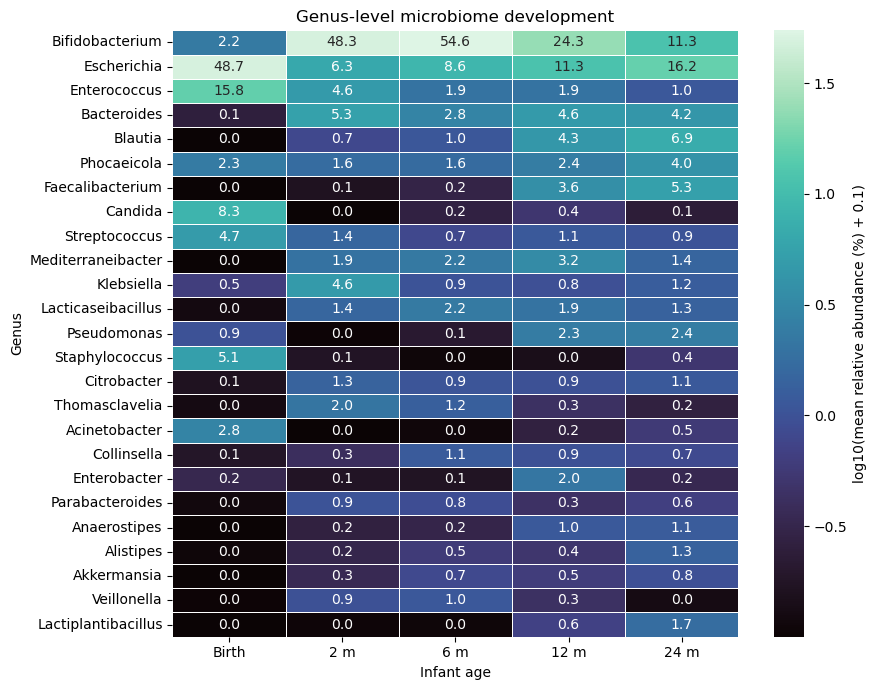

In [14]:
#Select the most abundant genera
top_genera = [
    name for name in age_means.mean().sort_values(ascending=False).index
    if name.split(";")[-1].replace("g__", "").strip() not in ["", "—", "__"]
][:25]

heatmap_data = age_means[top_genera].copy()

#Shorten genus names
heatmap_data.columns = [
    name.split(";")[-1].replace("g__", "")
    for name in heatmap_data.columns
]

# Transpose the table: genera become rows, ages become columns
heatmap_data = heatmap_data.T

#Apply log transformation to make smaller abundances visible
import numpy as np

heatmap_log = np.log10(heatmap_data + 0.1)

plt.figure(figsize=(9, 7))

sns.heatmap(
    heatmap_log,
    cmap="mako",
    annot=heatmap_data,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "log10(mean relative abundance (%) + 0.1)"}
)

plt.xlabel("Infant age")
plt.ylabel("Genus")
plt.title("Genus-level microbiome development")

plt.xticks(
    ticks=np.arange(5) + 0.5,
    labels=["Birth", "2 m", "6 m", "12 m", "24 m"],
    rotation=0
)

plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{output_dir}/figures/Top_genera_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Run Ancom-BC2 for statistical evidence

Acombc - 2 RUN 

In [16]:
! qiime composition ancombc2 \
    --i-table $data_dir/genus_table.qza \
    --m-metadata-file $data_dir/metadata_heatmap.tsv \
    --p-fixed-effects-formula "age_group_ordered" \
    --p-random-effects-formula "(1 | host_id)" \
    --p-reference-levels age_group_ordered::00_Birth \
    --p-p-adjust-method BH \
    --p-prevalence-cutoff 0.1 \
    --o-ancombc2-output $data_dir/ancombc2_age.qza

Saved FeatureData[ANCOMBC2Output] to: data/ancombc2_age.qza


In [18]:
! qiime composition da-barplot \
    --i-data $data_dir/ancombc2_age.qza \
    --o-visualization $data_dir/ancombc2_age_barplot.qzv

Saved Visualization to: data/ancombc2_age_barplot.qzv


In [ ]:
Visualization.load(f"{results_dir}/ancombc2_age_barplot.qzv")

In [20]:
! qiime composition tabulate \
    --i-data $data_dir/ancombc2_age.qza \
    --o-visualization $data_dir/ancombc2_age_results.qzv

Saved Visualization to: data/ancombc2_age_results.qzv


In [1]:
#Visualization.load(f"{results_dir}/ancombc2_age_results.qzv")

In [6]:
# Load your existing ANCOM-BC2 artifact
artifact = q2.Artifact.load(
    f"{output_dir}/ancombc2_age.qza"
)

# Access the results in a temporary directory
with tempfile.TemporaryDirectory() as tmp:
    artifact.export_data(tmp)

    lfc = pd.read_json(
        f"{tmp}/lfc.jsonl",
        lines=True
    )

    q_values = pd.read_json(
        f"{tmp}/q.jsonl",
        lines=True
    )

# Clean dataframes
lfc_clean = lfc.dropna(subset=["taxon"]).set_index("taxon")
q_clean = q_values.dropna(subset=["taxon"]).set_index("taxon")

print("Loaded:", len(lfc_clean), "taxa")


Loaded: 2466 taxa


In [7]:
b2 = lfc_clean["age_group_ordered::02_months"]
b6 = lfc_clean["age_group_ordered::06_months"]
b12 = lfc_clean["age_group_ordered::12_months"]
b24 = lfc_clean["age_group_ordered::24_months"]

transitions = pd.DataFrame({
    "Birth → 2m": b2,
    "2m → 6m": b6 - b2,
    "6m → 12m": b12 - b6,
    "12m → 24m": b24 - b12
})

display(transitions.head(20))

,Birth → 2m,2m → 6m,6m → 12m,12m → 24m
taxon,,,,
d__Bacteria;k__Pseudomonadati;p__Spirochaetota;c__Spirochaetia;o__Spirochaetales;f__Borreliaceae;g__Borreliella,0.486641,-1.253967,-0.128133,0.204598
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Micrococcales;f__Dermatophilaceae;g__Austwickia,0.277279,-1.244256,-0.315840,0.215913
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Hyphomicrobiales;f__Cohaesibacteraceae;g__Cohaesibacter,0.362891,-0.520905,-0.458243,0.499367
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Candidatus Pelagibacterales;f__Candidatus Pelagibacteraceae;g__Candidatus Pelagibacter,0.912682,-0.931295,-0.089561,0.082364
d__Bacteria;k__Pseudomonadati;p__Acidobacteriota;c__Terriglobia;o__Terriglobales;f__Acidobacteriaceae;g__Occallatibacter,0.000000,-0.943582,-0.588651,0.235211
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Micromonosporales;f__Micromonosporaceae;g__Micromonospora,1.753099,-0.403487,0.501249,-0.102827
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Gammaproteobacteria;o__Lysobacterales;f__Lysobacteraceae;g__Lysobacter,0.560407,-0.390932,0.409488,0.511884
d__Bacteria;k__Pseudomonadati;p__Bacteroidota;c__Chitinophagia;o__Chitinophagales;f__Chitinophagaceae;g__Chitinophaga,1.063405,-0.529282,0.023698,0.664633
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Alphaproteobacteria;o__Hyphomicrobiales;f__Phyllobacteriaceae;g__Mesorhizobium,1.149552,-0.229700,0.383625,0.241004


In [8]:
for comparison in transitions.columns:
    print(comparison)
    
    values = transitions[comparison].dropna()

    print("\nLargest estimated increases:")
    display(values.nlargest(10).to_frame("Estimated LFC"))


Birth → 2m

Largest estimated increases:


,Estimated LFC
taxon,
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Bifidobacteriales;f__Bifidobacteriaceae;g__Bifidobacterium,8.370640
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Mediterraneibacter,6.921392
d__Bacteria;k__Bacillati;p__Bacillota;c__Negativicutes;o__Veillonellales;f__Veillonellaceae;g__Veillonella,5.569880
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Blautia,5.190326
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Eubacteriales;f__Oscillospiraceae;g__Flavonifractor,5.083399
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Coriobacteriia;o__Eggerthellales;f__Eggerthellaceae;g__Eggerthella,4.921159
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Actinomycetales;f__Actinomycetaceae;g__Schaalia,4.920782
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Simiaoa,4.802595
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Eubacteriales;f__containing g__Intestinimonas;g__Intestinimonas,4.726872


2m → 6m

Largest estimated increases:


,Estimated LFC
taxon,
d__Viruses;k__Heunggongvirae;p__Uroviricota;c__Caudoviricetes;o__containing g__Oengusvirus;f__containing g__Oengusvirus;g__Oengusvirus,2.895124
d__Viruses;k__Bamfordvirae;p__Preplasmiviricota;c__Tectiliviricetes;o__Rowavirales;f__Adenoviridae;g__Mastadenovirus,2.333310
d__Bacteria;k__Bacillati;p__Bacillota;c__Bacilli;o__Lactobacillales;f__Lactobacillaceae;g__Lacticaseibacillus,1.811697
d__Bacteria;k__Bacillati;p__Bacillota;c__Negativicutes;o__Veillonellales;f__Veillonellaceae;g__Veillonella,1.738736
d__Eukaryota;k__Fungi;p__Ascomycota;c__Dipodascomycetes;o__Dipodascales;f__Trichomonascaceae;g__Sugiyamaella,1.548200
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Gammaproteobacteria;o__containing s__Abyssogena phaseoliformis symbiont;f__containing s__Abyssogena phaseoliformis symbiont;g__containing s__Abyssogena phaseoliformis symbiont,1.533848
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Gammaproteobacteria;o__containing s__endosymbiont of Euscepes postfasciatus;f__containing s__endosymbiont of Euscepes postfasciatus;g__containing s__endosymbiont of Euscepes postfasciatus,1.490343
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Enterocloster,1.480375
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Anaerostipes,1.451656


6m → 12m

Largest estimated increases:


,Estimated LFC
taxon,
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Eubacteriales;f__Oscillospiraceae;g__Faecalibacterium,3.736167
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Eubacteriales;f__Butyricicoccaceae;g__Butyricicoccus,2.436077
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnospira,2.392060
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Blautia,2.352949
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Eubacteriales;f__Oscillospiraceae;g__Ruminococcus,2.160189
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Agathobacter,2.008112
d__Viruses;k__Heunggongvirae;p__Uroviricota;c__Caudoviricetes;o__containing g__Lughvirus;f__containing g__Lughvirus;g__Lughvirus,1.962877
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Anaerobutyricum,1.946097
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Sellimonas,1.806952


12m → 24m

Largest estimated increases:


,Estimated LFC
taxon,
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Coriobacteriia;o__Eggerthellales;f__Eggerthellaceae;g__Adlercreutzia,2.573622
d__Viruses;k__Heunggongvirae;p__Uroviricota;c__Caudoviricetes;o__containing g__Skunavirus;f__containing g__Skunavirus;g__Skunavirus,2.555158
d__Bacteria;k__Bacillati;p__Bacillota;c__Erysipelotrichia;o__Erysipelotrichales;f__Coprobacillaceae;g__Faecalibacillus,2.497988
d__Bacteria;k__Pseudomonadati;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae;g__Alistipes,2.436800
d__Bacteria;k__Bacillati;p__Actinomycetota;c__Actinomycetes;o__Propionibacteriales;f__Propionibacteriaceae;g__Arachnia,2.435514
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Anaerobutyricum,2.403586
d__Bacteria;k__Pseudomonadati;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Phocaeicola,2.246888
d__Bacteria;k__Bacillati;p__Bacillota;c__Clostridia;o__Eubacteriales;f__Oscillospiraceae;g__Vescimonas,2.187930
d__Bacteria;k__Pseudomonadati;p__Pseudomonadota;c__Gammaproteobacteria;o__Enterobacterales;f__Hafniaceae;g__Obesumbacterium,2.035609


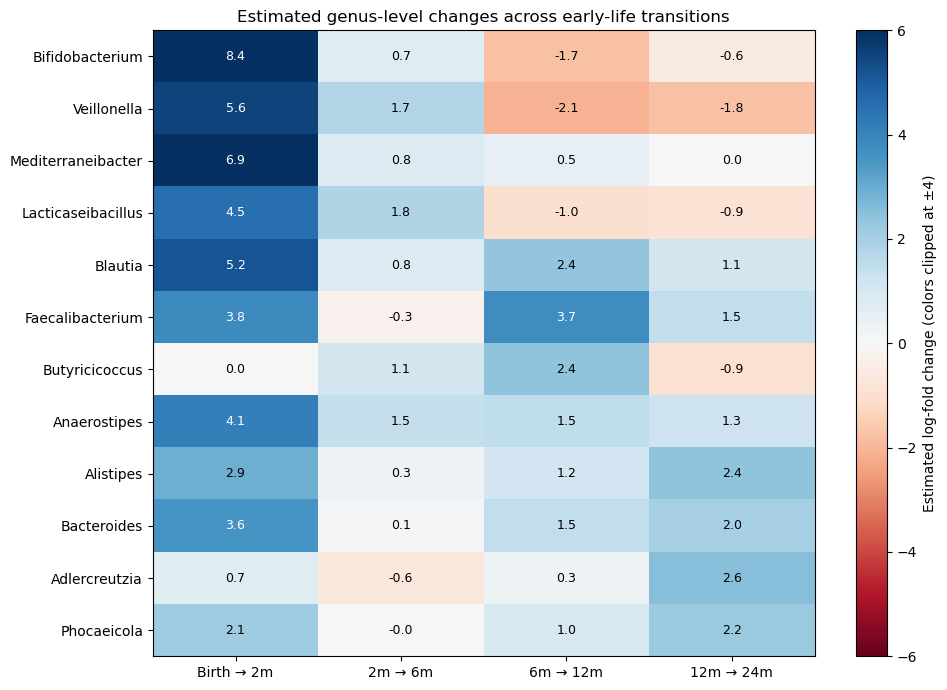

In [9]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Candidate genera to examine
genera = [
    "Bifidobacterium",
    "Veillonella",
    "Mediterraneibacter",
    "Lacticaseibacillus",
    "Blautia",
    "Faecalibacterium",
    "Butyricicoccus",
    "Anaerostipes",
    "Alistipes",
    "Bacteroides",
    "Adlercreutzia",
    "Phocaeicola"
]

# Keep bacterial taxa and extract their genus names
data = transitions.copy()
data = data[data.index.str.startswith("d__Bacteria;")]
data["Genus"] = data.index.to_series().str.extract(
    r"(?:^|;)g__([^;]+)$", expand=False
)

# Select candidate genera
plot_data = (
    data[data["Genus"].isin(genera)]
    .drop_duplicates("Genus")
    .set_index("Genus")
    .reindex(genera)
    .dropna(how="all")
)

# Draw heatmap with a symmetric scale
values = plot_data.to_numpy(dtype=float)
limit = np.nanmax(np.abs(values))

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    values,
    cmap="RdBu",
    vmin=-6,
    vmax=6,
    aspect="auto"
)

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        if np.isfinite(values[i, j]):
            ax.text(
                j, i, f"{values[i, j]:.1f}",
                ha="center", va="center",
                fontsize=9,
                color="white" if abs(values[i, j]) > 3 else "black"
            )

ax.set_xticks(range(len(plot_data.columns)))
ax.set_xticklabels(plot_data.columns)
ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels(plot_data.index)

ax.set_title(
    "Estimated genus-level changes across early-life transitions"
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Estimated log-fold change (colors clipped at ±4)")
plt.savefig(f"{output_dir}/figures/transitions_taxa_heatmap.png")
plt.tight_layout()
plt.show()